# Fairness in Recidivism Prediction: ProPublica vs. Northpointe on COMPAS

**MSBA 6341 — Responsible AI · Carlson School of Management, University of Minnesota**
**Author:** Parul Chaudhary

This notebook reproduces the empirical analysis behind the written report (`report/Fairness_in_Recidivism_Prediction_Report.pdf`). It tests both sides of the COMPAS debate:

- **ProPublica's allegation** — COMPAS errors are unequally distributed across races (*equal error rates*).
- **Northpointe's rebuttal** — a given score means the same thing regardless of race (*calibration / predictive parity*).

**Classification rule.** A COMPAS label of *Medium* or *High* is treated as a positive (high-risk) prediction; *Low* is negative. The outcome `two_year_recid` measures **rearrest within two years**, not proven reoffending.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

pd.set_option("display.precision", 3)

df = pd.read_csv("data/compas-scores.csv")
df["high_risk"] = (df["score_text"] != "Low").astype(int)          # Medium/High = positive prediction
df["black"] = (df["race"] == "African-American").astype(int)       # Caucasian = reference group
print(df.shape)
df.head()

(5278, 10)


,two_year_recid,score_text,decile_score,race,age_cat,c_charge_degree,sex,priors_count,high_risk,black
0,1,Low,3,African-American,25 - 45,F,Male,0,0,1
1,1,Low,4,African-American,Less than 25,F,Male,4,0,1
2,1,Medium,6,Caucasian,25 - 45,F,Male,14,1,0
3,0,Low,1,Caucasian,25 - 45,M,Female,0,0,0
4,0,Low,4,Caucasian,25 - 45,F,Male,0,0,0


## 1. Sample and base rates
The two groups have different observed rearrest rates. This matters: when base rates differ, calibration and equal error rates generally cannot both hold (Chouldechova, 2017; Kleinberg et al., 2017).

In [2]:
base = df.groupby("race").agg(N=("two_year_recid", "size"),
                              rearrest_rate=("two_year_recid", "mean"),
                              share_labeled_high=("high_risk", "mean"))
base

,N,rearrest_rate,share_labeled_high
race,,,
African-American,3175,0.523,0.576
Caucasian,2103,0.391,0.331


## 2. ProPublica's test — error rates by race
- **False-positive rate (FPR):** share of defendants *not* rearrested who were labeled Medium/High.
- **False-negative rate (FNR):** share of defendants who *were* rearrested but labeled Low.

In [3]:
def group_metrics(g):
    return pd.Series({
        "FPR": g.loc[g.two_year_recid == 0, "high_risk"].mean(),
        "FNR": 1 - g.loc[g.two_year_recid == 1, "high_risk"].mean(),
        "PPV": g.loc[g.high_risk == 1, "two_year_recid"].mean(),
        "Accuracy": (g.high_risk == g.two_year_recid).mean(),
    })

metrics = df.groupby("race").apply(group_metrics)
metrics

,FPR,FNR,PPV,Accuracy
race,,,,
African-American,0.423,0.285,0.650,0.649
Caucasian,0.220,0.496,0.595,0.672


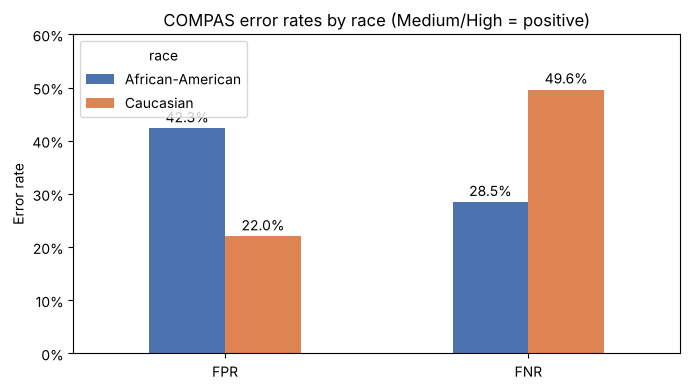

Black defendants who were NOT rearrested were 1.92x as likely to be labeled Medium/High.


In [4]:
ax = metrics[["FPR", "FNR"]].T.plot.bar(rot=0, figsize=(7, 4), color=["#4C72B0", "#DD8452"])
ax.set_ylabel("Error rate")
ax.set_ylim(0, 0.6)
ax.legend(title="race", loc="upper left")
ax.set_title("COMPAS error rates by race (Medium/High = positive)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v:.1%}" for v in c.datavalues], padding=2)
plt.tight_layout()
plt.savefig("outputs/error_rates_by_race.png", dpi=150)
plt.show()

fpr_ratio = metrics.loc["African-American", "FPR"] / metrics.loc["Caucasian", "FPR"]
print(f"Black defendants who were NOT rearrested were {fpr_ratio:.2f}x as likely to be labeled Medium/High.")

## 3. Northpointe's test — calibration and predictive parity
If COMPAS is calibrated, defendants with the same decile score should be rearrested at similar rates regardless of race.

In [5]:
calib = (df.groupby(["decile_score", "race"])["two_year_recid"]
           .agg(["mean", "size"]).unstack("race"))
calib

mean                       size          
race         African-American Caucasian African-American Caucasian
decile_score                                                      
1                       0.233     0.212              365       605
2                       0.303     0.312              346       321
3                       0.419     0.345              298       238
4                       0.469     0.403              337       243
5                       0.489     0.455              323       200
6                       0.588     0.581              318       160
7                       0.609     0.602              343       113
8                       0.714     0.750              301        96
9                       0.722     0.714              317        77
10                      0.837     0.700              227        50

Rearrest rate at decile 7:
                  sum  size   mean
race                              
African-American  209   343  0.609
Caucasian          68   113  0.602


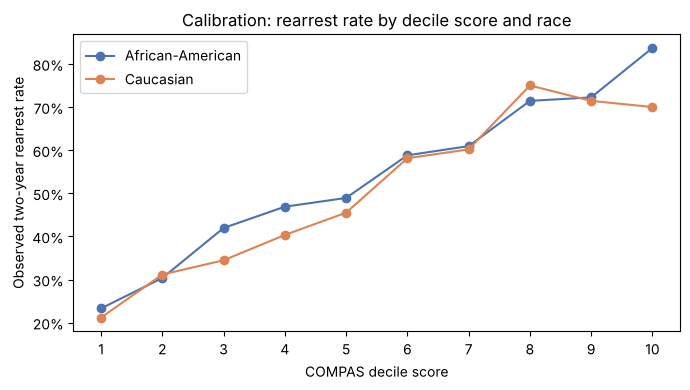

In [6]:
d7 = df[df.decile_score == 7].groupby("race")["two_year_recid"].agg(["sum", "size", "mean"])
print("Rearrest rate at decile 7:")
print(d7)

fig, ax = plt.subplots(figsize=(7, 4))
for race, color in [("African-American", "#4C72B0"), ("Caucasian", "#DD8452")]:
    s = calib["mean"][race]
    ax.plot(s.index, s.values, marker="o", label=race, color=color)
ax.set_xlabel("COMPAS decile score")
ax.set_ylabel("Observed two-year rearrest rate")
ax.set_title("Calibration: rearrest rate by decile score and race")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xticks(range(1, 11))
ax.legend()
plt.tight_layout()
plt.savefig("outputs/calibration_by_decile.png", dpi=150)
plt.show()

## 4. Does race predict the COMPAS label more than it predicts rearrest?
Two parallel logistic regressions with the same controls (`priors_count`, `age_cat`, `sex`, `c_charge_degree`; Caucasian = reference):
1. Outcome = COMPAS Medium/High label
2. Outcome = observed two-year rearrest

In [7]:
CONTROLS = {
    "Full controls": " + priors_count + C(age_cat) + C(sex) + C(c_charge_degree)",
    "Without priors_count": " + C(age_cat) + C(sex) + C(c_charge_degree)",
    "Race only": "",
}

def race_or(outcome, controls):
    m = smf.logit(f"{outcome} ~ black{controls}", data=df).fit(disp=0)
    lo, hi = np.exp(m.conf_int().loc["black"])
    return np.exp(m.params["black"]), lo, hi, m.pvalues["black"]

rows = []
for spec, ctrl in CONTROLS.items():
    or_l, lo_l, hi_l, p_l = race_or("high_risk", ctrl)
    or_r, lo_r, hi_r, p_r = race_or("two_year_recid", ctrl)
    rows.append({"Specification": spec,
                 "OR: COMPAS label": or_l, "95% CI (label)": f"{lo_l:.2f}-{hi_l:.2f}", "p (label)": p_l,
                 "OR: Rearrest": or_r, "95% CI (rearrest)": f"{lo_r:.2f}-{hi_r:.2f}", "p (rearrest)": p_r,
                 "OR ratio": or_l / or_r})

robust = pd.DataFrame(rows).set_index("Specification")
robust

,OR: COMPAS label,95% CI (label),p (label),OR: Rearrest,95% CI (rearrest),p (rearrest),OR ratio
Specification,,,,,,,
Full controls,1.625,1.42-1.86,1.326e-12,1.103,0.98-1.25,1.188e-01,1.473
Without priors_count,2.304,2.04-2.60,3.850e-42,1.466,1.31-1.65,9.892e-11,1.572
Race only,2.747,2.45-3.08,1.429e-66,1.710,1.53-1.91,5.797e-21,1.607


In [8]:
full = robust.loc["Full controls"]
print(f"Full controls -> Black defendants had {full['OR: COMPAS label']:.2f}x the odds of a Medium/High label "
      f"(95% CI {full['95% CI (label)']}, p = {full['p (label)']:.2g}),")
print(f"but only {full['OR: Rearrest']:.2f}x the odds of actual rearrest "
      f"(95% CI {full['95% CI (rearrest)']}, p = {full['p (rearrest)']:.3f}).")
print("OR ratio across specifications:", robust["OR ratio"].round(2).tolist())

Full controls -> Black defendants had 1.62x the odds of a Medium/High label (95% CI 1.42-1.86, p = 1.3e-12),
but only 1.10x the odds of actual rearrest (95% CI 0.98-1.25, p = 0.119).
OR ratio across specifications: [1.47, 1.57, 1.61]


## 5. Interpretation

| Question | Finding |
|---|---|
| Does ProPublica's allegation hold? | **Yes.** Black defendants who were not rearrested were ~1.9x as likely to be labeled Medium/High (FPR 42.3% vs. 22.0%); white defendants who were rearrested were more often labeled Low (FNR 49.6% vs. 28.5%). |
| Does Northpointe's rebuttal hold? | **Also yes.** PPV is similar (65.0% vs. 59.5%) and rearrest rates track closely within decile scores (decile 7: 60.9% vs. 60.2%). |
| Is the label disparity explained by the controls? | **No.** Race raises the odds of a Medium/High label far more than it raises the odds of rearrest, and the ~1.5-1.6x gap persists across specifications. |
| Can both fairness criteria be satisfied? | **Not with different base rates** (52.3% vs. 39.1%) — the impossibility result. Fairness becomes a policy choice. |

**Position:** in decisions that can remove liberty (bail, sentencing, parole), the distribution of *harmful errors* should take priority over calibration. A COMPAS label should not independently justify harsher treatment unless an independent audit shows the false-positive-rate gap is below a publicly defined threshold — paired with recurring group-level audits, documented judicial use, and a defendant's right to examine and challenge the score.

**Limitation:** the outcome is *rearrest*, which also reflects policing intensity — so calibration to this proxy does not by itself establish fairness.